# PROYECTO INTEGRADOR - COMPLEJIDAD COMPUTACIONAL


## Importamos los recursos necesarios

In [35]:
import numpy as np
import matplotlib.pyplot as plt
import time
import random

## Problema 1:  SLOWSORT vs QUICKSORT

In [36]:
def slowsort(arr, i=0, j=None):
    """Complejidad: O(n^(log n))"""
    # Divide la lista en dos mitades, ordena recursivamente la primera mitad, luego la segunda. Después, compara los elementos máximos de ambas mitades y coloca el mayor de todos al final de la lista. Finalmente, llama recursivamente a la función para ordenar el resto de la lista (excluyendo el máximo que ya colocó).
    # Complejidad: $O(n^{\log n})$. Es extremadamente lento; no es polinómico, pero tampoco es tan lento como el peor caso exponencial puro
    if j is None:
        j = len(arr) - 1
        arr = arr.copy()

    if i >= j:
        return arr

    m = (i + j) // 2
    arr = slowsort(arr, i, m)
    arr = slowsort(arr, m + 1, j)

    if arr[j] < arr[m]:
        arr[j], arr[m] = arr[m], arr[j]

    arr = slowsort(arr, i, j - 1)
    return arr


def quicksort(arr):
    """Complejidad: O(n log n) promedio, O(n²) peor caso"""
    # Utiliza la estrategia "divide y vencerás". Elige un elemento llamado pivote (en tu código, el último elemento). Luego, particiona la lista en tres subgrupos: elementos menores que el pivote, iguales al pivote y mayores que el pivote. Se llama a sí mismo recursivamente para ordenar los subgrupos de menores y mayores.
    # Complejidad: En promedio es $O(n \log n)$, lo cual es muy rápido.
    if len(arr) <= 1:
        return arr

    pivot = arr[-1]
    menores = [x for x in arr[:-1] if x < pivot]
    iguales = [x for x in arr if x == pivot]
    mayores = [x for x in arr[:-1] if x > pivot]

    return quicksort(menores) + iguales + quicksort(mayores)

## Problema 2: DETERMINANTE vs PERMANENTE

In [37]:
def determinante_recursivo(matriz):
    """Complejidad: O(n!)"""
    # Usa la expansión por cofactores (Laplace). Recorre la primera fila y, para cada elemento, multiplica dicho elemento por el determinante de la submatriz que queda al eliminar su fila y columna. Crucialmente, alterna los signos (suma, resta, suma...).
    # Complejidad: $O(n!)$. Crece factorialmente, lo que lo hace inutilizable para matrices grandes.
    n = len(matriz)

    if n == 1:
        return matriz[0][0]

    if n == 2:
        return matriz[0][0] * matriz[1][1] - matriz[0][1] * matriz[1][0]

    det = 0
    for j in range(n):
        submatriz = [fila[:j] + fila[j+1:] for fila in matriz[1:]]
        cofactor = ((-1) ** j) * matriz[0][j] * determinante_recursivo(submatriz)
        det += cofactor

    return det


def permanente(matriz):
    """Complejidad: O(n! * n) - #P-completo"""
    # La lógica es casi idéntica a la del determinante recursivo, pero con una diferencia fundamental: no alterna los signos; todo se suma.
    # Complejidad: $O(n! \cdot n)$. A diferencia del determinante, no existen atajos rápidos conocidos para el permanente. Es un problema de clase #P-completo, uno de los más difíciles en computación.
    n = len(matriz)

    if n == 1:
        return matriz[0][0]

    perm = 0
    for j in range(n):
        submatriz = [fila[:j] + fila[j+1:] for fila in matriz[1:]]
        perm += matriz[0][j] * permanente(submatriz)

    return perm

## Problema 3: TEST DE PRIMALIDAD SOLOVAY-STRASSEN

In [38]:
def simbolo_jacobi(a, n):
    """Calcula el símbolo de Jacobi (a/n)"""
    # Elige un número aleatorio $a$ y verifica una propiedad matemática específica (el criterio de Euler usando el símbolo de Jacobi). Si la propiedad no se cumple, el número es definitivamente compuesto. Si se cumple, es "probablemente primo". Al repetir esto $k$ veces (en tu código $k=20$), la probabilidad de error se vuelve infinitesimalmente pequeña ($1/2^k$).
    # Complejidad: $O(k \cdot \log^3 n)$. Es muy eficiente, lo que permite probar números gigantescos.
    if n <= 0 or n % 2 == 0:
        return 0

    a = a % n
    resultado = 1

    while a != 0:
        while a % 2 == 0:
            a //= 2
            if n % 8 in [3, 5]:
                resultado = -resultado

        a, n = n, a
        if a % 4 == 3 and n % 4 == 3:
            resultado = -resultado

        a = a % n

    return resultado if n == 1 else 0


def solovay_strassen(n, k=20):
    """Complejidad: O(k * log³ n) - Clase RP"""
    if n <= 1:
        return False
    if n <= 3:
        return True
    if n % 2 == 0:
        return False

    for _ in range(k):
        a = random.randint(2, n - 1)
        x = simbolo_jacobi(a, n)

        if x == 0:
            return False

        y = pow(a, (n - 1) // 2, n)

        if x % n != y:
            return False

    return True

Problema 4: TORRES DE HANOI

In [39]:
def torres_hanoi(n, origen='A', destino='C', auxiliar='B', movimientos=None):
    """Complejidad: O(2^n) - Movimientos: 2^n - 1"""
    # Es el ejemplo clásico de recursión.
    # Para mover $n$ discos:
    # Mueve $n-1$ discos de Origen a Auxiliar.
    # Mueve el disco más grande de Origen a Destino.
    # Mueve los $n-1$ discos de Auxiliar a Destino.
    # Complejidad: $O(2^n)$. El número de movimientos crece exponencialmente. Con 3 discos son 7 pasos; con 64 discos, el universo se acabaría antes de terminar.
    if movimientos is None:
        movimientos = []

    if n == 1:
        movimientos.append((origen, destino))
        return movimientos

    torres_hanoi(n - 1, origen, auxiliar, destino, movimientos)
    movimientos.append((origen, destino))
    torres_hanoi(n - 1, auxiliar, destino, origen, movimientos)

    return movimientos


def configuracion_hanoi(n):
    """Retorna configuración final y lista de movimientos"""
    movimientos = torres_hanoi(n)

    torres = {
        'A': list(range(n, 0, -1)),
        'B': [],
        'C': []
    }

    for origen, destino in movimientos:
        disco = torres[origen].pop()
        torres[destino].append(disco)

    return torres, movimientos

## Problema 5: ALGORITMO DE FLEURY (Camino Euleriano)

In [40]:
def es_puente(grafo, u, v):
    """Determina si la arista (u,v) es un puente"""
    # Comienza en un nodo con grado impar (si existe) o cualquiera. En cada paso, elige cruzar una arista hacia un vecino. La regla de oro es: "No cruces un puente a menos que no tengas otra opción". Al seguir esta regla, te aseguras de no quedarte aislado en una parte del grafo antes de haber recorrido todo.
    # Complejidad: $O(E^2)$ donde $E$ es el número de aristas. Es costoso porque verificar si una arista es un puente en cada paso consume tiempo.
    grafo[u].remove(v)
    grafo[v].remove(u)

    visitados = set()

    def dfs(nodo):
        visitados.add(nodo)
        for vecino in grafo[nodo]:
            if vecino not in visitados:
                dfs(vecino)

    nodos = [n for n in grafo if grafo[n] or any(n in grafo[x] for x in grafo)]
    if nodos:
        dfs(nodos[0])

    es_puente_resultado = len(visitados) < len(nodos)

    grafo[u].append(v)
    grafo[v].append(u)

    return es_puente_resultado


def fleury(grafo_original):
    """Complejidad: O(E²)"""
    grafo = {k: v[:] for k, v in grafo_original.items()}

    grados_impares = [v for v in grafo if len(grafo[v]) % 2 == 1]

    if len(grados_impares) not in [0, 2]:
        return None

    inicio = grados_impares[0] if grados_impares else list(grafo.keys())[0]

    camino = [inicio]
    actual = inicio

    while any(grafo[v] for v in grafo):
        for vecino in grafo[actual][:]:
            if len(grafo[actual]) == 1 or not es_puente(grafo, actual, vecino):
                grafo[actual].remove(vecino)
                grafo[vecino].remove(actual)
                camino.append(vecino)
                actual = vecino
                break

    return camino

## Problema 6: CIFRADO XOR

In [41]:
def xor_cifrado(mensaje, clave):
    """Complejidad: O(n)"""
    # Aplica la operación lógica XOR ($\oplus$) a nivel de bits (o en este caso, códigos ASCII) entre cada carácter del mensaje y la clave repetida.
    # Complejidad: $O(n)$. Es lineal respecto a la longitud del mensaje, lo que lo hace extremadamente rápido.
    resultado = []

    for i, char in enumerate(mensaje):
        clave_char = clave[i % len(clave)]
        resultado.append(chr(ord(char) ^ ord(clave_char)))

    return ''.join(resultado)


def xor_descifrado(mensaje_cifrado, clave):
    """Descifrado XOR (idéntico al cifrado)"""
    return xor_cifrado(mensaje_cifrado, clave)


## ANÁLISIS Y GRAFICACIÓN

In [42]:
def analizar_complejidades():
    """Genera gráficas de análisis de complejidad temporal"""
    fig, axes = plt.subplots(3, 2, figsize=(15, 12))
    fig.suptitle('Análisis de Complejidad Temporal', fontsize=16, fontweight='bold')

    # 1. Slowsort vs Quicksort
    ax = axes[0, 0]
    tamaños = range(5, 31, 5)
    tiempos_slow = []
    tiempos_quick = []

    for n in tamaños:
        arr = list(range(n, 0, -1))

        if n <= 15:
            inicio = time.time()
            slowsort(arr)
            tiempos_slow.append(time.time() - inicio)
        else:
            tiempos_slow.append(None)

        inicio = time.time()
        quicksort(arr)
        tiempos_quick.append(time.time() - inicio)

    ax.plot([n for n, t in zip(tamaños, tiempos_slow) if t],
            [t for t in tiempos_slow if t], 'ro-', label='Slowsort O(n^(log n))', linewidth=2)
    ax.plot(tamaños, tiempos_quick, 'bo-', label='Quicksort O(n log n)', linewidth=2)
    ax.set_xlabel('Tamaño (n)')
    ax.set_ylabel('Tiempo (s)')
    ax.set_title('Slowsort vs Quicksort')
    ax.legend()
    ax.grid(True, alpha=0.3)

    # 2. Determinante vs Permanente
    ax = axes[0, 1]
    tamaños = range(2, 9)
    tiempos_det = []
    tiempos_perm = []

    for n in tamaños:
        matriz = [[random.randint(1, 10) for _ in range(n)] for _ in range(n)]

        inicio = time.time()
        determinante_recursivo(matriz)
        tiempos_det.append(time.time() - inicio)

        if n <= 7:
            inicio = time.time()
            permanente(matriz)
            tiempos_perm.append(time.time() - inicio)
        else:
            tiempos_perm.append(None)

    ax.plot(tamaños, tiempos_det, 'go-', label='Determinante O(n!)', linewidth=2)
    ax.plot([n for n, t in zip(tamaños, tiempos_perm) if t],
            [t for t in tiempos_perm if t], 'mo-', label='Permanente O(n!·n)', linewidth=2)
    ax.set_xlabel('Tamaño matriz (n×n)')
    ax.set_ylabel('Tiempo (s)')
    ax.set_title('Determinante vs Permanente')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_yscale('log')

    # 3. Solovay-Strassen
    ax = axes[1, 0]
    numeros = [101, 1009, 10007, 100003, 1000003]
    tiempos_ss = []

    for n in numeros:
        inicio = time.time()
        solovay_strassen(n, k=20)
        tiempos_ss.append(time.time() - inicio)

    ax.plot(numeros, tiempos_ss, 'c-', linewidth=2, marker='s', markersize=8)
    ax.set_xlabel('Número a probar')
    ax.set_ylabel('Tiempo (s)')
    ax.set_title('Test Solovay-Strassen O(k·log³n)')
    ax.set_xscale('log')
    ax.grid(True, alpha=0.3)

    # 4. Torres de Hanoi
    ax = axes[1, 1]
    discos = range(1, 21)
    movimientos_teoricos = [2**n - 1 for n in discos]

    ax.plot(discos, movimientos_teoricos, 'ro-', linewidth=2)
    ax.set_xlabel('Número de discos (n)')
    ax.set_ylabel('Movimientos (2^n - 1)')
    ax.set_title('Torres de Hanoi O(2^n)')
    ax.set_yscale('log')
    ax.grid(True, alpha=0.3)

    # 5. Fleury
    ax = axes[2, 0]
    tamaños_grafo = [4, 6, 8, 10, 12]
    tiempos_fleury = []

    for n in tamaños_grafo:
        grafo = {i: [(i-1) % n, (i+1) % n] for i in range(n)}

        inicio = time.time()
        fleury(grafo)
        tiempos_fleury.append(time.time() - inicio)

    ax.plot(tamaños_grafo, tiempos_fleury, 'y-', linewidth=2, marker='D', markersize=8)
    ax.set_xlabel('Número de vértices')
    ax.set_ylabel('Tiempo (s)')
    ax.set_title('Algoritmo de Fleury O(E²)')
    ax.grid(True, alpha=0.3)

    # 6. XOR Cipher
    ax = axes[2, 1]
    longitudes = range(100, 10001, 1000)
    tiempos_xor = []

    for n in longitudes:
        mensaje = 'A' * n
        clave = 'clave'

        inicio = time.time()
        xor_cifrado(mensaje, clave)
        tiempos_xor.append(time.time() - inicio)

    ax.plot(longitudes, tiempos_xor, 'ko-', linewidth=2)
    ax.set_xlabel('Longitud del mensaje')
    ax.set_ylabel('Tiempo (s)')
    ax.set_title('Cifrado XOR O(n)')
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    return fig

## Mostrar los resultados:

PROYECTO INTEGRADOR - COMPLEJIDAD COMPUTACIONAL

1. SLOWSORT vs QUICKSORT
----------------------------------------------------------------------
Array original: [5, 2, 8, 1, 9]
Quicksort: [1, 2, 5, 8, 9]
Slowsort: [1, 2, 5, 8, 9]

2. DETERMINANTE vs PERMANENTE
----------------------------------------------------------------------
Matriz:
[[1 2]
 [3 4]]
Determinante: -2
Permanente: 10

3. TEST DE PRIMALIDAD SOLOVAY-STRASSEN
----------------------------------------------------------------------
17: PROBABLEMENTE PRIMO
18: COMPUESTO
97: PROBABLEMENTE PRIMO
100: COMPUESTO
1009: PROBABLEMENTE PRIMO

4. TORRES DE HANOI
----------------------------------------------------------------------
Número de discos: 3
Número de movimientos: 7
Configuración final: {'A': [], 'B': [], 'C': [3, 2, 1]}

5. ALGORITMO DE FLEURY
----------------------------------------------------------------------
Grafo: {0: [1, 2], 1: [0, 2], 2: [0, 1]}
Camino Euleriano: [0, 1, 2, 0]

6. CIFRADO XOR
------------------------

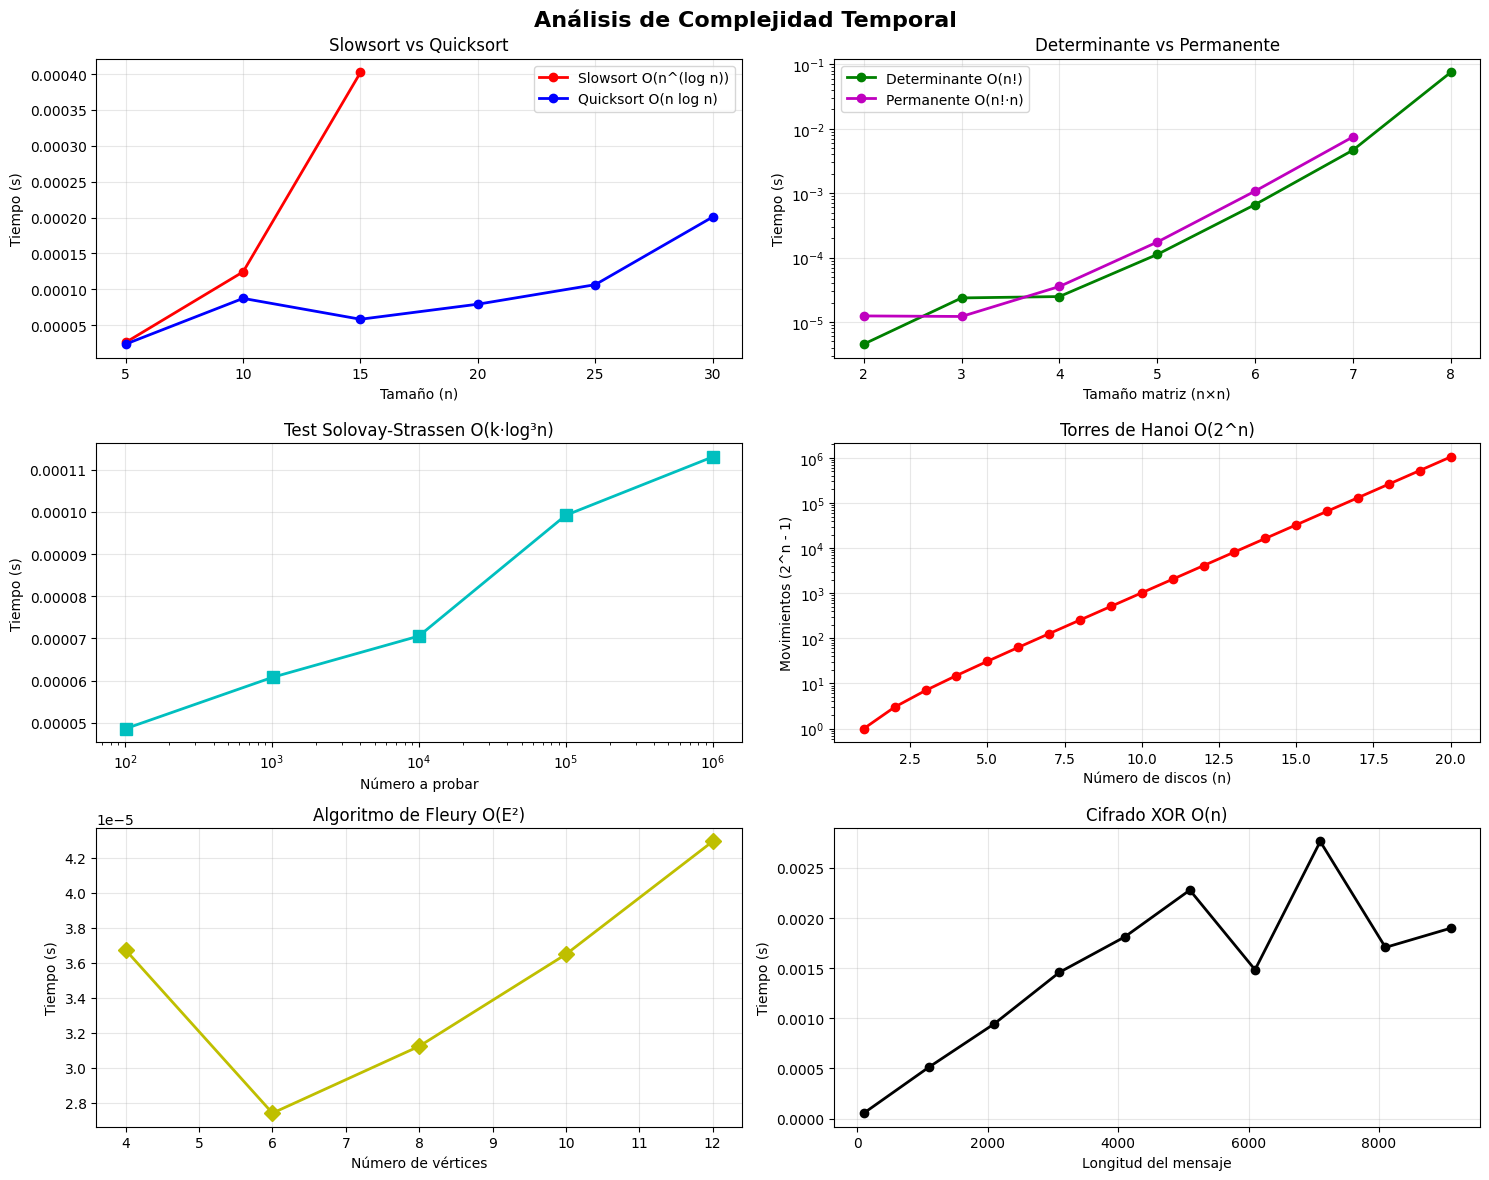

Gráficas guardadas en 'analisis_complejidad1.pdf'


In [43]:
def main():
    print("="*70)
    print("PROYECTO INTEGRADOR - COMPLEJIDAD COMPUTACIONAL")
    print("="*70)

    # 1. Slowsort vs Quicksort
    print("\n1. SLOWSORT vs QUICKSORT")
    print("-" * 70)
    arr = [5, 2, 8, 1, 9]
    print(f"Array original: {arr}")
    print(f"Quicksort: {quicksort(arr)}")
    print(f"Slowsort: {slowsort(arr)}")

    # 2. Determinante vs Permanente
    print("\n2. DETERMINANTE vs PERMANENTE")
    print("-" * 70)
    matriz = [[1, 2], [3, 4]]
    print(f"Matriz:\n{np.array(matriz)}")
    print(f"Determinante: {determinante_recursivo(matriz)}")
    print(f"Permanente: {permanente(matriz)}")

    # 3. Solovay-Strassen
    print("\n3. TEST DE PRIMALIDAD SOLOVAY-STRASSEN")
    print("-" * 70)
    numeros_prueba = [17, 18, 97, 100, 1009]
    for n in numeros_prueba:
        es_primo = solovay_strassen(n)
        print(f"{n}: {'PROBABLEMENTE PRIMO' if es_primo else 'COMPUESTO'}")

    # 4. Torres de Hanoi
    print("\n4. TORRES DE HANOI")
    print("-" * 70)
    n_discos = 3
    config, movs = configuracion_hanoi(n_discos)
    print(f"Número de discos: {n_discos}")
    print(f"Número de movimientos: {len(movs)}")
    print(f"Configuración final: {config}")

    # 5. Fleury
    print("\n5. ALGORITMO DE FLEURY")
    print("-" * 70)
    grafo = {0: [1, 2], 1: [0, 2], 2: [0, 1]}
    camino = fleury(grafo)
    print(f"Grafo: {grafo}")
    print(f"Camino Euleriano: {camino}")

    # 6. XOR Cipher
    print("\n6. CIFRADO XOR")
    print("-" * 70)
    mensaje = "Hola Mundo"
    clave = "secreto"
    cifrado = xor_cifrado(mensaje, clave)
    descifrado = xor_descifrado(cifrado, clave)
    print(f"Mensaje original: {mensaje}")
    print(f"Clave: {clave}")
    print(f"Mensaje cifrado: {repr(cifrado)}")
    print(f"Mensaje descifrado: {descifrado}")

    # Generar gráficas
    print("\n" + "="*70)
    print("GRÁFICAS DE ANÁLISIS...")
    print("="*70)
    fig = analizar_complejidades()
    plt.savefig('analisis_complejidad.pdf', dpi=300, bbox_inches='tight')
    plt.show()
    print("Gráficas guardadas en 'analisis_complejidad1.pdf'")


if __name__ == "__main__":
    main()